In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, Activation, Concatenate, Conv2DTranspose, BatchNormalization
from tensorflow.keras.applications import EfficientNetB0
import numpy as np
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import MeanIoU

# Para comparar os modelos a unica coisa que muda é a linha de chamada do modelo

In [ ]:
# hiper parametros
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.00001

In [4]:
# carregando os dados de treino e validação
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

In [ ]:
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [6]:
def decoder_efficientnet(inputs,skips, filters):
    x = Conv2DTranspose(filters, (2,2), strides=2, padding="same")(inputs)
    x = Concatenate()([x,skips])
    x = convolucao(x,filters)
    return x

In [ ]:
def efficientnet_unet(input_shape):
    inputs = Input(input_shape)

    # o efficientnet ja normaliza a imagem dentro do proprio modelo
    # entao nao precisa de preprocess_input como no resnet
    efficientnet = EfficientNetB0(include_top=False, weights="imagenet", input_tensor=inputs)

    # o efficientnet reduz 5 vezes (288 ate 9), por isso aqui sao 4 skips do encoder mais a propria imagem
    s1 = inputs
    s2 = efficientnet.get_layer("block2a_expand_activation").output
    s3 = efficientnet.get_layer("block3a_expand_activation").output
    s4 = efficientnet.get_layer("block4a_expand_activation").output
    s5 = efficientnet.get_layer("block6a_expand_activation").output

    # base da arquitetura
    b1 = efficientnet.get_layer("top_activation").output

    # cinco blocos pois o efficientnet reduz a imagem 5 vezes, o ultimo volta para 288x288 com a imagem original de skip
    d1 = decoder_efficientnet(b1, s5, 512)
    d2 = decoder_efficientnet(d1, s4, 256)
    d3 = decoder_efficientnet(d2, s3, 128)
    d4 = decoder_efficientnet(d3, s2, 64)
    d5 = decoder_efficientnet(d4, s1, 32)

    outputs = Conv2D(5,1, padding='same',activation='softmax')(d5)
    # saida multiclasse

    model = Model(inputs,outputs)

    return model

In [8]:
model = efficientnet_unet((height_img, width_img, canais))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 288, 288,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 288, 288,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 288, 288,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 289, 289,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 144, 144,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 144, 144,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 144, 144,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 144, 144,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 144, 144,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 144, 144,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 144, 144,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 144, 144,  │        512 │ block1a_se_excit

 Total params: 17,535,304 (66.89 MB)

 Trainable params: 17,489,313 (66.72 MB)

 Non-trainable params: 45,991 (179.66 KB)

In [ ]:
model.compile(optimizer=Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False, name='mean_io_u')])
# loss é a sparse padrao para esse teste

In [11]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet.keras'

In [ ]:
# checks, mesmos dos outros modelos
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.000001, verbose=1)
checks = [checkpointer, lr_reducer, early_stopper]

In [13]:
# treinando o modelo
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - loss: 1.5638 - mean_io_u: 0.0804
Epoch 1: val_mean_io_u improved from None to 0.15052, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 300s 561ms/step - loss: 1.4796 - mean_io_u: 0.1003 - val_loss: 1.2651 - val_mean_io_u: 0.1505 - learning_rate: 1.0000e-05
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - loss: 1.3075 - mean_io_u: 0.1473
Epoch 2: val_mean_io_u improved from 0.15052 to 0.17687, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0_U-Net/modelo_unet_efficientnet.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/EFFICIENTNETB0

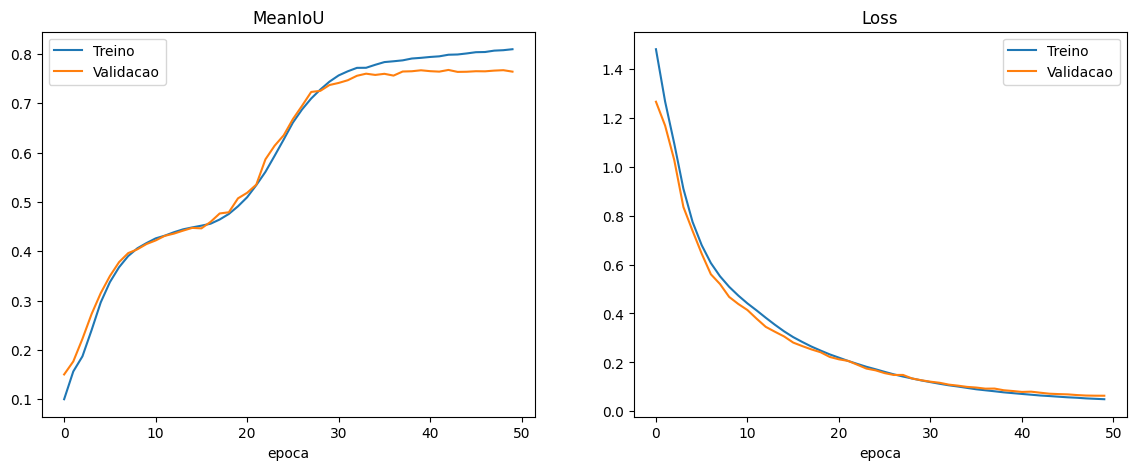

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss')
plt.xlabel('epoca')
plt.legend()

plt.show()